In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [3]:
# Load dataset
df = pd.read_csv(
    '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv',
    sep=';'
)

df.columns = df.columns.str.strip()

# Separate features and target
X = df.drop(columns=['Target'])
y = df['Target']

print("Dataset Shape:", df.shape)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Dataset Shape: (4424, 37)
Features Shape: (4424, 36)
Target Shape: (4424,)


In [4]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3539, 36)
Testing Data: (885, 36)


In [5]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 20],
    'min_samples_split': [2, 5]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best F1-Score:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best F1-Score: 0.6871


In [6]:
# Best Random Forest Model

best_model = grid_search.best_estimator_

print("Best Model:")
print(best_model)

Best Model:
RandomForestClassifier(max_depth=20, min_samples_split=5, n_estimators=200,
                       random_state=42)


In [7]:
# Predictions using the Best Model

y_pred = best_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [8]:
# Model Evaluation

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average='macro'), 4))
print("Recall:", round(recall_score(y_test, y_pred, average='macro'), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, average='macro'), 4))

Accuracy: 0.7763
Precision: 0.7371
Recall: 0.6898
F1-Score: 0.7026


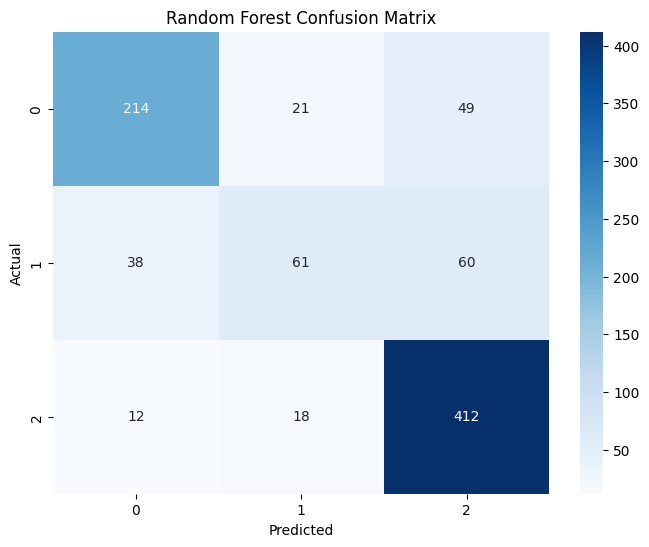

In [9]:
# Confusion Matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')

plt.show()

In [10]:
# Best Hyperparameters from Grid Search

results = pd.DataFrame(
    grid_search.cv_results_
)

results = results.sort_values(
    by='rank_test_score'
)

display(
    results[
        ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    ].head(10)
)

,params,mean_test_score,std_test_score,rank_test_score
7,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.687144,0.008796,1
6,"{'max_depth': 20, 'min_samples_split': 5, 'n_e...",0.686454,0.008354,2
4,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.684497,0.009084,3
3,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.683759,0.011421,4
5,"{'max_depth': 20, 'min_samples_split': 2, 'n_e...",0.683681,0.010799,5
2,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.681469,0.010914,6
1,"{'max_depth': None, 'min_samples_split': 2, 'n...",0.680713,0.008943,7
0,"{'max_depth': None, 'min_samples_split': 2, 'n...",0.675466,0.011959,8


In [11]:
# Use the best model and its predictions

optimized_model = best_model
optimized_pred = y_pred

print("Optimized Random Forest Model Ready!")

Optimized Random Forest Model Ready!


In [12]:
# Evaluate optimized model
optimized_accuracy = accuracy_score(y_test, optimized_pred)
optimized_precision = precision_score(y_test, optimized_pred, average='macro')
optimized_recall = recall_score(y_test, optimized_pred, average='macro')
optimized_f1 = f1_score(y_test, optimized_pred, average='macro')

print("Optimized Random Forest Results")
print("--------------------------------")
print("Accuracy:", round(optimized_accuracy, 4))
print("Precision:", round(optimized_precision, 4))
print("Recall:", round(optimized_recall, 4))
print("F1-Score:", round(optimized_f1, 4))

Optimized Random Forest Results
--------------------------------
Accuracy: 0.7763
Precision: 0.7371
Recall: 0.6898
F1-Score: 0.7026


In [13]:
# Recreate baseline model
baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

baseline_model.fit(X_train, y_train)

# Make baseline predictions
baseline_pred = baseline_model.predict(X_test)

# Calculate baseline metrics
accuracy = accuracy_score(y_test, baseline_pred)
precision = precision_score(y_test, baseline_pred, average='macro')
recall = recall_score(y_test, baseline_pred, average='macro')
f1 = f1_score(y_test, baseline_pred, average='macro')

print("Baseline Results Calculated Successfully!")

Baseline Results Calculated Successfully!


In [14]:
# Compare baseline and optimized models

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline': [accuracy, precision, recall, f1],
    'Optimized': [
        optimized_accuracy,
        optimized_precision,
        optimized_recall,
        optimized_f1
    ]
})

print(comparison)

      Metric  Baseline  Optimized
0   Accuracy  0.767232   0.776271
1  Precision  0.721395   0.737131
2     Recall  0.680208   0.689765
3   F1-Score  0.691628   0.702575


In [15]:
# 5-Fold Cross Validation

cv_scores = cross_val_score(
    grid_search.best_estimator_,
    X_train,
    y_train,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

print("Cross Validation Scores:", np.round(cv_scores, 4))
print("Mean CV F1:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

Cross Validation Scores: [0.6806 0.6804 0.6764 0.6946 0.7003]
Mean CV F1: 0.6865
Standard Deviation: 0.0093


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

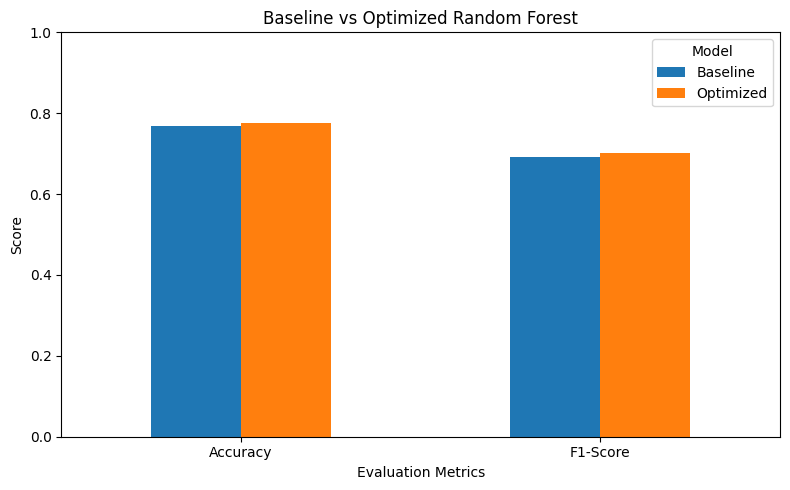

In [17]:
# Compare Baseline and Optimized models

comparison_plot = comparison.set_index('Metric')[['Baseline', 'Optimized']]

comparison_plot.loc[['Accuracy', 'F1-Score']].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Baseline vs Optimized Random Forest')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

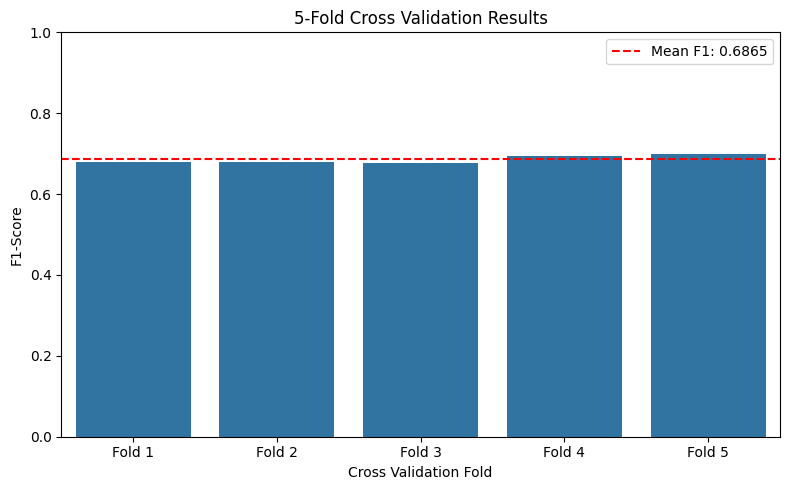

In [18]:
# Plot Cross Validation Scores

plt.figure(figsize=(8, 5))

sns.barplot(
    x=[f'Fold {i}' for i in range(1, 6)],
    y=cv_scores
)

plt.axhline(
    y=cv_scores.mean(),
    linestyle='--',
    color='red',
    label=f'Mean F1: {cv_scores.mean():.4f}'
)

plt.title('5-Fold Cross Validation Results')
plt.xlabel('Cross Validation Fold')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()